In [1]:
%pip install opencv-python matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


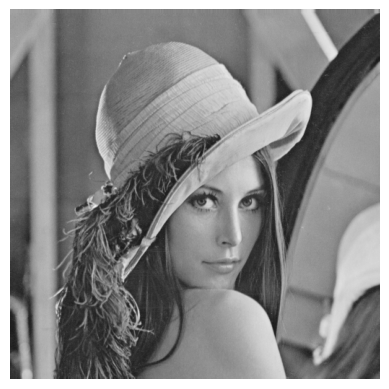

In [3]:
#Path
from pathlib import Path
import cv2 as cv
import matplotlib.pyplot as plt
import numpy as np

project_root = Path.cwd()
project_root = project_root.parent
image_path = project_root / 'Images' / 'img2.tif'
img2 = cv.imread(str(image_path))

plt.imshow(cv.cvtColor(img2, cv.COLOR_BGR2RGB))
plt.axis('off')
plt.show()

# Marr-Hildreth Edge Detector

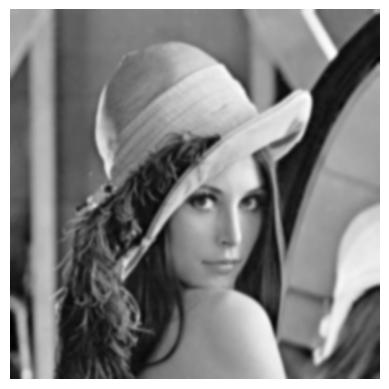

In [68]:
#convert to gray scale
gray = cv.cvtColor(img2, cv.COLOR_BGR2GRAY)
#Apply Gaussian filter
img2_gaussian = cv.GaussianBlur(gray, (13, 13), sigmaX=2)
plt.imshow(img2_gaussian, cmap='gray')
plt.axis('off')
plt.show()

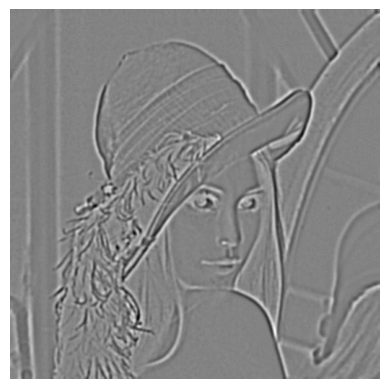

In [74]:
#apply Laplacian filter
img2_laplacian = cv.Laplacian(img2_gaussian, cv.CV_32F, ksize=5)
plt.imshow(img2_laplacian, cmap='gray')
plt.axis('off')
plt.show()

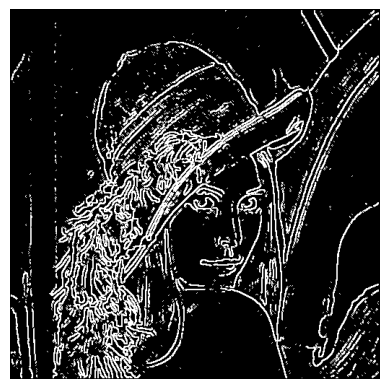

In [83]:
#Zero crossing
THRESH = 60
# THRESH = 0
directions = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
zero_crossing = np.zeros_like(img2_laplacian, dtype=np.uint8)
for i in range(1, img2_laplacian.shape[0] - 1):
    for j in range(1, img2_laplacian.shape[1] - 1):
            for dx, dy in directions:
                new_x, new_y = i + dx, j + dy
                if (img2_laplacian[i, j] > 0 and img2_laplacian[new_x, new_y] < 0) or (img2_laplacian[i, j] < 0 and img2_laplacian[new_x, new_y] > 0):
                    if abs(img2_laplacian[i, j] - img2_laplacian[new_x, new_y]) > THRESH:
                        zero_crossing[i, j] = 255
                        break

plt.imshow(zero_crossing, cmap='gray')
plt.axis('off')
plt.show()

Canny Edge Detector

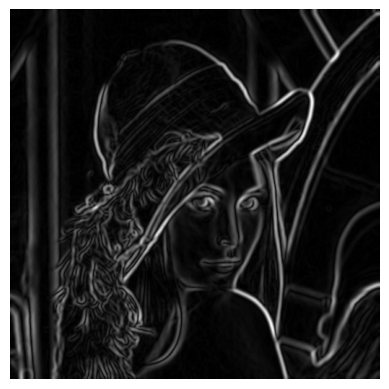

In [85]:
#Implement Sobel filter
sobel_x = cv.Sobel(img2_gaussian, cv.CV_32F, 1, 0, ksize=3)
sobel_y = cv.Sobel(img2_gaussian, cv.CV_32F, 0, 1, ksize=3)
img2_sobel = np.sqrt(sobel_x**2 + sobel_y**2)

        
plt.imshow(img2_sobel, cmap='gray')
plt.axis('off')
plt.show()
#

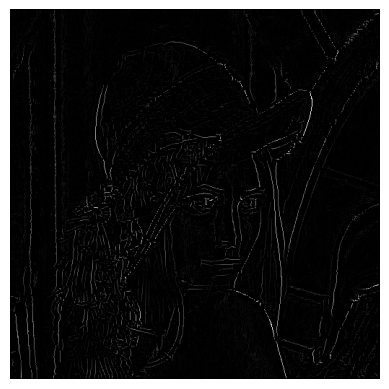

In [ ]:
#get orientation
orientation = np.arctan2(sobel_y, sobel_x) * (180 / np.pi)

orientation = (orientation + 180) % 180
#Non-maximum suppression
non_max_suppressed = np.zeros_like(img2_sobel, dtype=np.float32)
for i in range(1, img2_sobel.shape[0] - 1):
    for j in range(1, img2_sobel.shape[1] - 1):
        angle = orientation[i, j]
        current = img2_sobel[i, j]
        
        if (0 <= angle < 22.5) or (157.5 <= angle < 180):#0 degrees
            neighbor1 = img2_sobel[i, j - 1]
            neighbor2 = img2_sobel[i, j + 1]
        elif 22.5 <= angle < 67.5:#45 degrees
            neighbor1 = img2_sobel[i - 1, j + 1]
            neighbor2 = img2_sobel[i + 1, j - 1]
        elif 67.5 <= angle < 112.5:#90 degrees
            neighbor1 = img2_sobel[i - 1, j]
            neighbor2 = img2_sobel[i + 1, j]
        else:#135 degrees
            neighbor1 = img2_sobel[i - 1, j - 1]
            neighbor2 = img2_sobel[i + 1, j + 1]

        if current >= neighbor1 and current >= neighbor2:
            non_max_suppressed[i, j] = current

plt.imshow(non_max_suppressed, cmap='gray')
plt.axis('off')
plt.show()

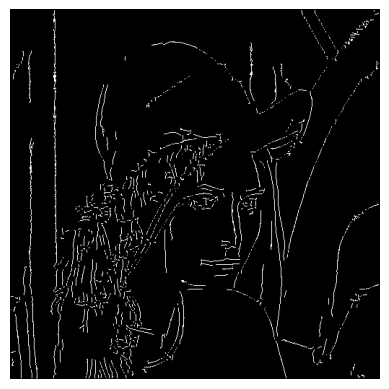

In [ ]:
from collections import deque
#Double thresholds
high_threshold = 0.2 * non_max_suppressed.max()
low_threshold = 0.1 * non_max_suppressed.max()
STRONG = 255
WEAK = 75

thresholded = np.zeros_like(non_max_suppressed, dtype=np.uint8)

strong_pixels = non_max_suppressed >= high_threshold
weak_pixels = (non_max_suppressed >= low_threshold) & (non_max_suppressed < high_threshold)

thresholded[strong_pixels] = STRONG
thresholded[weak_pixels] = WEAK

final_edges = thresholded.copy()

q = deque()
strong_locations = np.argwhere(final_edges == STRONG)
for y, x in strong_locations:
    q.append((y, x))

directions = [(-1, -1), (-1, 0), (-1, 1),( 0, -1),( 0, 1),( 1, -1), ( 1, 0), ( 1, 1)]

#Follow weak edges connected to strong edges
while q:
    y, x = q.popleft()
    for dy, dx in directions:
        new_y = y + dy
        new_x = x + dx

        if (0 <= new_y < final_edges.shape[0] and 0 <= new_x < final_edges.shape[1]
            and final_edges[new_y, new_x] == WEAK):
            final_edges[new_y, new_x] = STRONG
            q.append((new_y, new_x))


# Remove weak edges that were never connected to strong ones
final_edges[final_edges != STRONG] = 0
plt.imshow(final_edges, cmap='gray')
plt.axis('off')
plt.show()